# Umbrales de faltantes y análisis de sensibilidad

**Pregunta predictiva del proyecto:** Dado un préstamo que Lending Club acaba de aprobar, y usando únicamente la información disponible el día del desembolso, ¿qué probabilidad hay de que termine declarado incobrable (`Charged Off`) en lugar de pagarse por completo (`Fully Paid`)?

**Pregunta del experimento:** ¿cómo afecta la cobertura mínima exigida a las variables que entran en cada corte temporal y al desempeño de los modelos?

Se integran los experimentos `09e` (10 %, 30 %, 50 % y 75 %) y `09f` (análisis de sensibilidad 50 % frente a 75 %). Las tablas y figuras se leen de los artefactos guardados: no se ejecuta una nueva búsqueda ni se usa el test para seleccionar.

In [1]:
from pathlib import Path
import sys, os
candidatos_raiz = [Path(os.environ.get("PROYECTO_ML_RAIZ", Path.cwd())).resolve()]
if "__file__" in globals():
    candidatos_raiz.append(Path(__file__).resolve().parent)
raiz_encontrada = next((p for base in candidatos_raiz for p in [base, *base.parents]
                        if (p / "src/config.py").is_file()), None)
if raiz_encontrada is None:
    raise FileNotFoundError("Abra Jupyter dentro del proyecto o defina PROYECTO_ML_RAIZ.")
if str(raiz_encontrada) not in sys.path:
    sys.path.insert(0, str(raiz_encontrada))
from src.rutas import raiz_proyecto
RAIZ = raiz_proyecto(raiz_encontrada)
carpeta = RAIZ


## Reproducción de los experimentos

Cada control ejecuta la implementación conservada en `src/`, con sus semillas, parámetros y cortes originales. Las tablas históricas posteriores permanecen como referencia. Active solo el experimento que quiera regenerar; las salidas nuevas se guardan en `outputs/reproducciones/`, sin reemplazar las métricas históricas. La selección, imputación, indicadores y escalado se ajustan con el entrenamiento de cada corte. Las comparaciones de 59 variables siguen siendo exploratorias.


In [2]:
from src.reproducir import ejecutar_experimento
REGENERAR_UMBRALES = False
if REGENERAR_UMBRALES:
    carpeta_nueva, tablas_nuevas = ejecutar_experimento("umbrales")
    print("Resultados nuevos:", carpeta_nueva)
    for nombre_tabla, tabla in tablas_nuevas.items():
        display(tabla)


In [3]:
from src.reproducir import ejecutar_experimento
REGENERAR_SENSIBILIDAD = False
# Use una carpeta nueva comparacion_umbrales_faltantes para analizar una reproducción.
FUENTE_UMBRALES = None  # None conserva la referencia histórica; o Path a tablas regeneradas.
if REGENERAR_SENSIBILIDAD:
    carpeta_nueva, tablas_nuevas = ejecutar_experimento("sensibilidad", referencias=FUENTE_UMBRALES)
    print("Resultados nuevos:", carpeta_nueva)
    for nombre_tabla, tabla in tablas_nuevas.items():
        display(tabla)


## 1. Comparación de umbrales

,modelo,umbral_pct,variables_promedio,variables_min,variables_max,ROC_AUC_promedio,ROC_AUC_desviacion,PR_AUC_promedio,PR_AUC_desviacion,columnas_transformadas_promedio,cortes_convergencia
0,gradient_boosting,10,33.75,26,57,0.7033,0.0213,0.3593,0.0740,107.75,0
1,gradient_boosting,30,51.25,26,60,0.7105,0.0259,0.3687,0.0769,125.25,0
2,gradient_boosting,50,51.50,26,60,0.7104,0.0259,0.3687,0.0769,125.50,0
3,gradient_boosting,75,61.75,61,63,0.7135,0.0203,0.3721,0.0707,135.75,0
4,regresion_logistica,10,33.75,26,57,0.6962,0.0193,0.3522,0.0689,107.75,0
5,regresion_logistica,30,51.25,26,60,0.7022,0.0239,0.3593,0.0711,125.25,0
6,regresion_logistica,50,51.50,26,60,0.7022,0.0239,0.3593,0.0711,125.50,0
7,regresion_logistica,75,61.75,61,63,0.7055,0.0182,0.3626,0.0654,135.75,0
8,svm_lineal,10,33.75,26,57,0.6961,0.0195,0.3515,0.0688,107.75,0
9,svm_lineal,30,51.25,26,60,0.7022,0.0241,0.3586,0.0711,125.25,0


,anio_validacion,umbral_pct,conservar,excluir
0,2013,10,26,69
1,2013,30,26,69
2,2013,50,26,69
3,2013,75,61,34
4,2014,10,26,69
5,2014,30,59,36
6,2014,50,60,35
7,2014,75,61,34
8,2015,10,26,69
9,2015,30,60,35


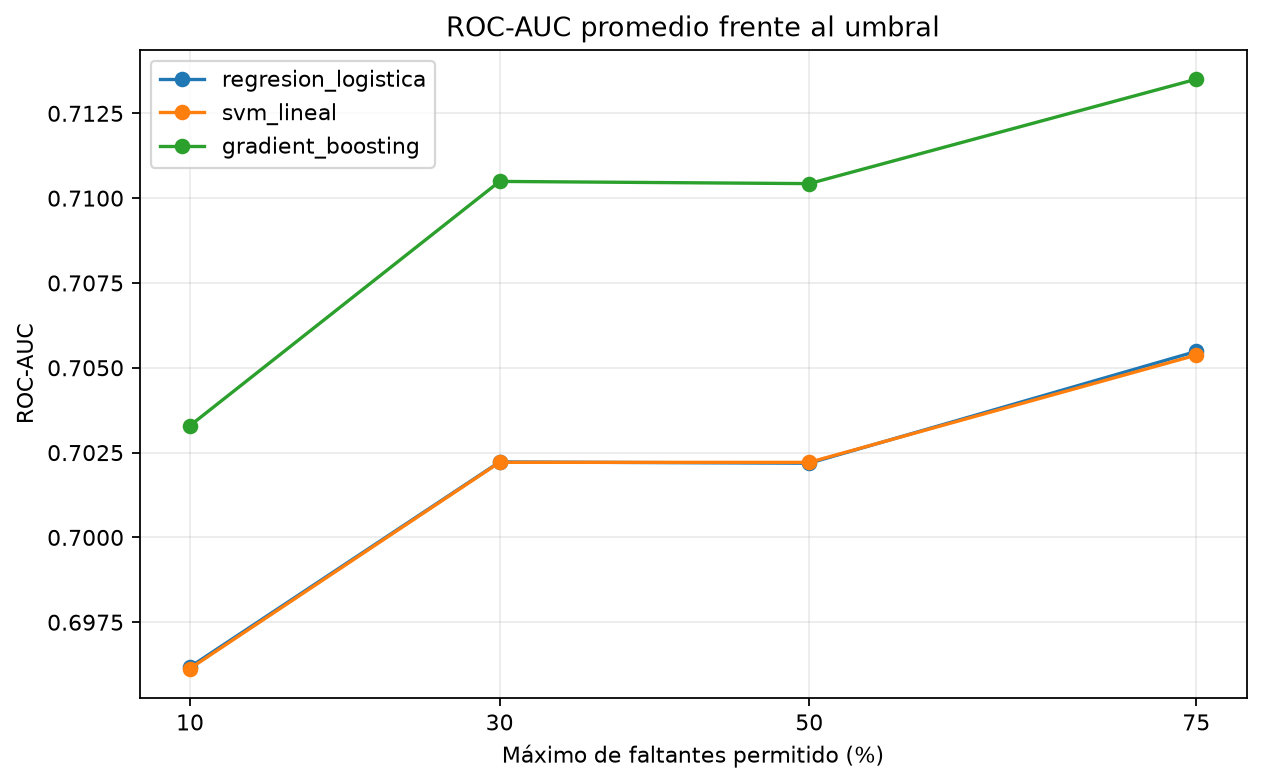

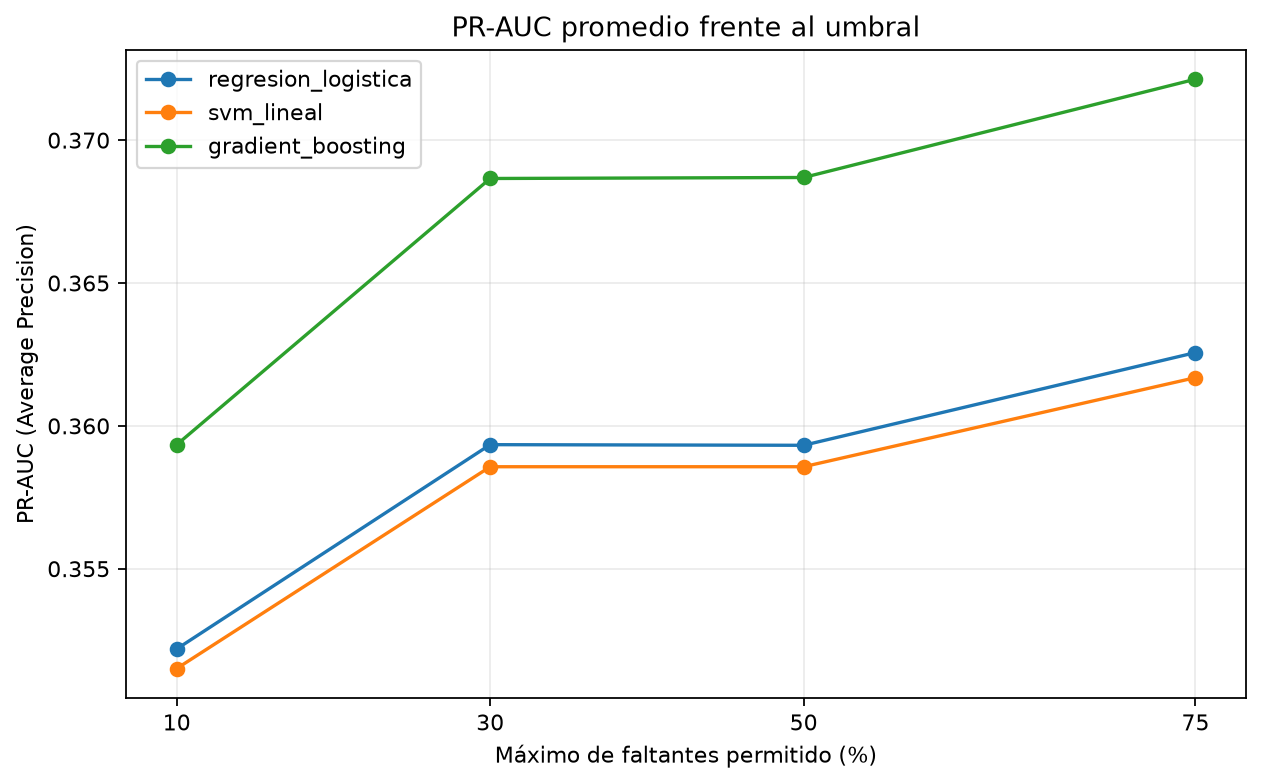

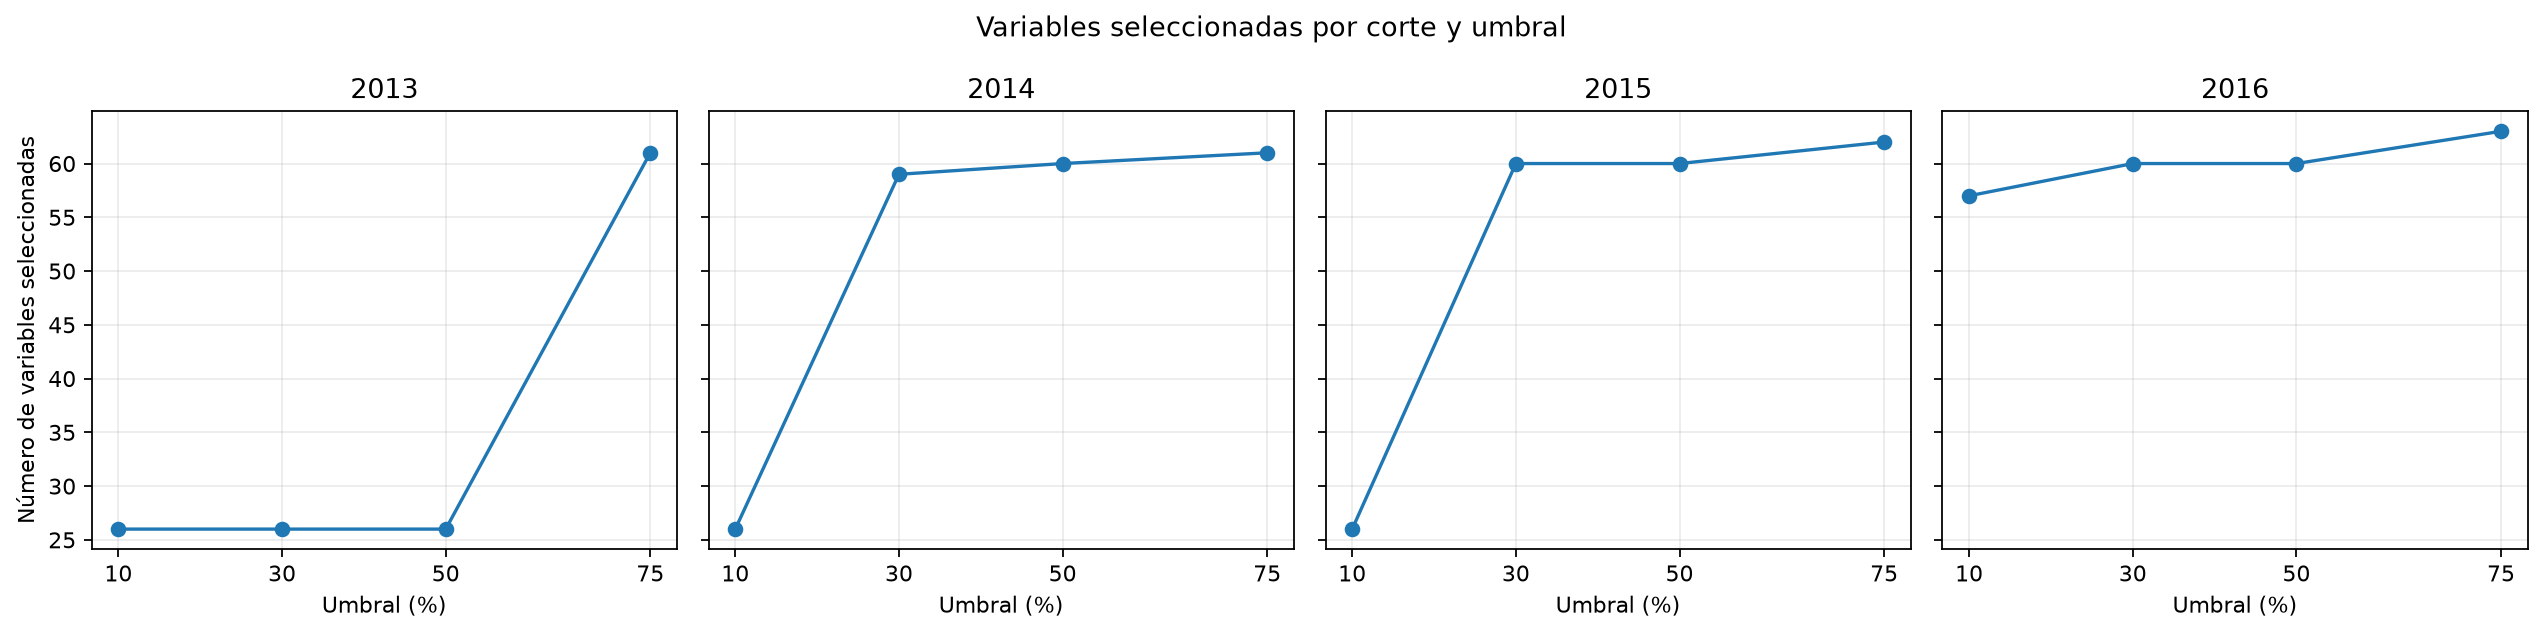

In [4]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

RAIZ = raiz_proyecto()
if not (RAIZ / "outputs").exists():
    RAIZ = RAIZ.parent
CARPETA = RAIZ / "outputs" / "comparacion_umbrales_faltantes"
resumen_umbrales = pd.read_csv(CARPETA / "resumen_promedios_y_variabilidad.csv")
conteos = pd.read_csv(CARPETA / "conteo_variables_por_corte_y_umbral.csv")
display(resumen_umbrales.round(4))
display(conteos)
for nombre in ["01_roc_auc_promedio.png", "02_pr_auc_promedio.png", "03_variables_por_corte.png"]:
    display(Image(filename=str(CARPETA / nombre)))

## 2. Sensibilidad 50 % vs. 75 %

,modelo,umbral_pct,variables_promedio,ROC_AUC_promedio,PR_AUC_promedio,desv_ROC_AUC,desv_PR_AUC
0,regresion_logistica,50,51.50,0.7022,0.3593,0.0239,0.0711
1,regresion_logistica,75,61.75,0.7055,0.3626,0.0182,0.0654
2,svm_lineal,50,51.50,0.7022,0.3586,0.0241,0.0711
3,svm_lineal,75,61.75,0.7054,0.3617,0.0187,0.0657
4,gradient_boosting,50,51.50,0.7104,0.3687,0.0259,0.0769
5,gradient_boosting,75,61.75,0.7135,0.3721,0.0203,0.0707


,modelo,variables_adicionales_promedio,diferencia_ROC_AUC,diferencia_PR_AUC,desv_ROC_50,desv_ROC_75,desv_PR_50,desv_PR_75
0,regresion_logistica,10.25,0.0033,0.0032,0.0239,0.0182,0.0711,0.0654
1,svm_lineal,10.25,0.0032,0.0031,0.0241,0.0187,0.0711,0.0657
2,gradient_boosting,10.25,0.0031,0.0034,0.0259,0.0203,0.0769,0.0707


,variables_adicionales_distintas,delta_ROC_AUC_promedio_GB,delta_PR_AUC_promedio_GB,anios_ROC_AUC_mejora,anios_PR_AUC_mejora,variables_con_aumento_temporal_posible,recomendacion
0,37,0.003078,0.00344,1,3,31,50% provisional; 75% alternativa si la cobertu...


,modelo,anio_validacion,variables_50,variables_75,ROC_50,ROC_75,delta_ROC_75_menos_50,PR_50,PR_75,delta_PR_75_menos_50
0,gradient_boosting,2013,26.0,61.0,0.674595,0.687117,0.012523,0.264998,0.278940,0.013942
1,gradient_boosting,2014,60.0,61.0,0.713169,0.713046,-0.000123,0.356152,0.355949,-0.000203
2,gradient_boosting,2015,60.0,62.0,0.736327,0.736241,-0.000085,0.420679,0.420696,0.000017
3,gradient_boosting,2016,60.0,63.0,0.717622,0.717620,-0.000003,0.432942,0.432948,0.000005
4,regresion_logistica,2013,26.0,61.0,0.669694,0.682673,0.012979,0.263071,0.275846,0.012774
5,regresion_logistica,2014,60.0,61.0,0.705325,0.705456,0.000131,0.348369,0.348468,0.000099
6,regresion_logistica,2015,60.0,62.0,0.727135,0.727174,0.000038,0.408355,0.408405,0.000050
7,regresion_logistica,2016,60.0,63.0,0.706595,0.706628,0.000033,0.417487,0.417539,0.000052
8,svm_lineal,2013,26.0,61.0,0.669406,0.681868,0.012462,0.262263,0.274429,0.012165
9,svm_lineal,2014,60.0,61.0,0.705886,0.705932,0.000046,0.347800,0.347838,0.000038


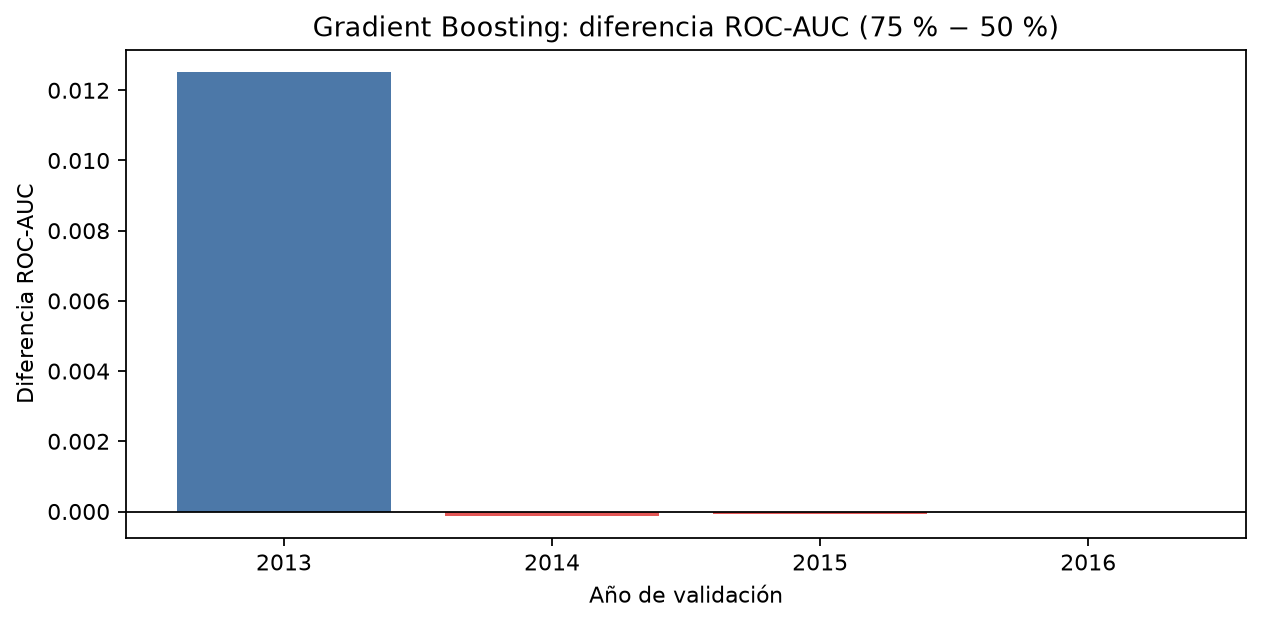

In [5]:
CARPETA_SENS = RAIZ / "outputs" / "analisis_sensibilidad_faltantes"
comparacion_50_75 = pd.read_csv(CARPETA_SENS / "comparacion_promedios_50_vs_75.csv")
diferencias = pd.read_csv(CARPETA_SENS / "diferencias_promedio_50_vs_75.csv")
recomendacion = pd.read_csv(CARPETA_SENS / "resumen_decision.csv")
por_anio = pd.read_csv(CARPETA_SENS / "metricas_anuales_50_vs_75.csv")
display(comparacion_50_75.round(4))
display(diferencias.round(4))
display(recomendacion)
display(por_anio)
display(Image(filename=str(CARPETA_SENS / "03_delta_roc_anual.png")))

## Conclusión

En los resultados guardados, el umbral de 75 % obtiene promedios mayores que 50 % para los tres modelos, incluida una diferencia de ROC-AUC de aproximadamente 0.0031 para Gradient Boosting. El informe de sensibilidad recomendó 50 % como regla provisional y mantuvo 75 % como alternativa, porque la mayor cobertura de variables depende de que esa disponibilidad histórica se mantenga. La decisión de umbral es una regla de preparación, no una prueba de que las variables adicionales causen la mejora.

Las tablas por año deben leerse junto con la diferencia de cantidad de variables por corte; los resultados no autorizan a decir que 50 % sea universalmente óptimo.